# Greeks Analysis - ETH + BTC

Deep dive into **delta, gamma, vega, theta** for every option on the chain.

For an **option buyer**, Greeks tell you:

- **Delta** = how much premium moves per $1 move in spot
- **Gamma** = how fast delta changes (acceleration)
- **Vega** = how much premium moves per 1% IV change
- **Theta** = how much premium you lose per day (your enemy)

**Sections:**

1. Fetch chain + compute Greeks
2. Greeks table for liquid contracts
3. Delta by strike (probability of expiring ITM)
4. Gamma concentration (where delta changes fastest)
5. Vega exposure (vol sensitivity map)
6. Theta decay (how much time costs you)
7. Greeks vs distance to expiry
8. Greeks heatmaps (strike × expiry)
9. Best contracts by Greeks profile
10. Buyer's verdict per coin

## Setup

In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from datetime import datetime, timezone
import time

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (13, 5)

DERIBIT = 'https://www.deribit.com/api/v2/public'
COINS = ['BTC', 'ETH']
print('ready')

ready


## 1. Fetch live chain and compute Greeks

Black-Scholes formulas:

```
d1 = (ln(S/K) + 0.5*sigma^2*T) / (sigma*sqrt(T))
d2 = d1 - sigma*sqrt(T)

Call price = S*N(d1) - K*N(d2)
Put  price = K*N(-d2) - S*N(-d1)

Delta_call = N(d1)
Delta_put  = N(d1) - 1
Gamma      = N'(d1) / (S * sigma * sqrt(T))
Vega       = S * N'(d1) * sqrt(T) / 100
Theta      = -(S*N'(d1)*sigma) / (2*sqrt(T)) / 365
```

Assumes European options, risk-free rate = 0.

In [2]:
def fetch_chain(currency):
    r = requests.get(f'{DERIBIT}/get_book_summary_by_currency',
                     params={'currency': currency, 'kind': 'option'}, timeout=20)
    r.raise_for_status()
    return r.json()['result']


def parse_name(name):
    parts = name.split('-')
    if len(parts) != 4: return None
    try:
        _, exp, strike, kind = parts
        dt = datetime.strptime(exp, '%d%b%y').replace(tzinfo=timezone.utc, hour=8)
        return int(dt.timestamp() * 1000), float(strike), kind
    except (ValueError, IndexError):
        return None


def bs_greeks(S, K, T, sigma, kind):
    if T <= 0 or sigma <= 0:
        return None
    d1 = (np.log(S/K) + 0.5*sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    pdf = norm.pdf(d1)
    delta = norm.cdf(d1) if kind == 'C' else norm.cdf(d1) - 1
    gamma = pdf / (S * sigma * np.sqrt(T))
    vega  = S * pdf * np.sqrt(T) / 100
    theta = -(S * pdf * sigma) / (2 * np.sqrt(T)) / 365
    price = S*norm.cdf(d1) - K*norm.cdf(d2) if kind == 'C' else K*norm.cdf(-d2) - S*norm.cdf(-d1)
    return {'delta': float(delta), 'gamma': float(gamma),
            'vega': float(vega), 'theta': float(theta), 'bs_price': float(price)}


frames = []
for cur in COINS:
    raw = fetch_chain(cur)
    now_ms = int(time.time() * 1000)
    rows = []
    for r in raw:
        p = parse_name(r['instrument_name'])
        if p is None: continue
        rows.append({
            'coin': cur, 'expiry': p[0], 'strike': p[1], 'kind': p[2],
            'ts': now_ms,
            'mark': r.get('mark_price'),
            'bid': r.get('bid_price'), 'ask': r.get('ask_price'),
            'iv': r.get('mark_iv'),
            'oi': r.get('open_interest') or 0,
            'volume': r.get('volume') or 0,
            'underlying_price': r.get('underlying_price'),
        })
    frames.append(pd.DataFrame(rows))
    print(f'{cur}: {len(rows)} contracts')
    time.sleep(0.3)

df = pd.concat(frames, ignore_index=True)
df['days'] = (df['expiry'] - df['ts']) / 86_400_000
df['iv_dec'] = df['iv'] / 100.0

spots = {}
for cur in COINS:
    s = df[df.coin == cur]
    v = s[s.underlying_price.notna()]
    spots[cur] = float(v.underlying_price.iloc[0]) if len(v) else float(s.strike.median())

print(f'\ntotal: {len(df)} contracts')
for k, v in spots.items(): print(f'  {k} spot: {v:,.2f}')

BTC: 924 contracts
ETH: 794 contracts

total: 1718 contracts
  BTC spot: 80,448.56
  ETH spot: 2,312.31


In [3]:
enriched = []
for cur in COINS:
    s = df[(df.coin == cur) & df.iv_dec.notna() & df.days.between(1, 365)]
    for _, r in s.iterrows():
        g = bs_greeks(spots[cur], r.strike, r.days/365, r.iv_dec, r.kind)
        if g:
            enriched.append({**r.to_dict(), **g})

ek = pd.DataFrame(enriched)
print(f'contracts with Greeks: {len(ek)}')
ek[['coin','strike','kind','days','iv_dec','delta','gamma','vega','theta','bs_price','mark']].head(10)

contracts with Greeks: 1590


,coin,strike,kind,days,iv_dec,delta,gamma,vega,theta,bs_price,mark
0,BTC,73000.0,P,33.601392,0.4198,-0.204266,2.766885e-05,69.204529,-43.230444,1250.790273,0.015545
1,BTC,79500.0,P,2.601392,0.3427,-0.335625,1.566403e-04,24.760943,-163.096833,525.243321,0.008101
2,BTC,104000.0,C,61.601392,0.3815,0.059382,9.371521e-06,39.051602,-12.092410,303.517824,0.004021
3,BTC,60000.0,C,334.601392,0.4323,0.820036,7.879311e-06,202.090026,-13.054865,24449.280372,0.326959
4,BTC,70000.0,C,33.601392,0.4475,0.862700,2.010823e-05,53.612728,-35.700450,11257.176752,0.139932
5,BTC,106000.0,P,5.601392,0.6476,-0.999661,1.922315e-07,0.123643,-0.714746,25551.992845,0.322875
6,BTC,90000.0,P,5.601392,0.4218,-0.983038,1.001011e-05,4.193582,-15.789406,9576.661177,0.123444
7,BTC,105000.0,P,243.601392,0.3881,-0.752228,1.239930e-05,207.856767,-16.557625,27789.294779,0.312617
8,BTC,112000.0,P,152.601392,0.3857,-0.885329,9.654854e-06,100.762173,-12.733819,32563.860984,0.383114
9,BTC,58000.0,C,61.601392,0.5313,0.946093,6.235405e-06,36.185840,-15.604791,22884.659225,0.287354


## 2. Greeks summary table

Median Greeks per coin - the typical option profile.

In [4]:
summary = ek.groupby(['coin', 'kind']).agg(
    n_contracts=('strike', 'count'),
    delta_median=('delta', 'median'),
    gamma_median=('gamma', 'median'),
    vega_median=('vega', 'median'),
    theta_median=('theta', 'median'),
).round(5)
print(summary.to_string())

           n_contracts  delta_median  gamma_median  vega_median  theta_median
coin kind                                                                    
BTC  C             432       0.37835       0.00001     39.05888     -18.78229
     P             432      -0.62165       0.00001     39.05888     -18.78229
ETH  C             363       0.26713       0.00033      0.98088      -0.78779
     P             363      -0.73287       0.00033      0.98088      -0.78779


## 3. Delta by strike - probability of expiring ITM

**What this tells you:**

- Delta ~ 0.50 = ATM (coin flip ITM at expiry)
- Delta 0.30-0.50 = reasonable leverage, real probability
- Delta > 0.70 = deep ITM (expensive, low leverage)
- Delta < 0.20 = lottery ticket (cheap but unlikely)
- **As a buyer, target 0.30-0.50 delta** — best risk/reward

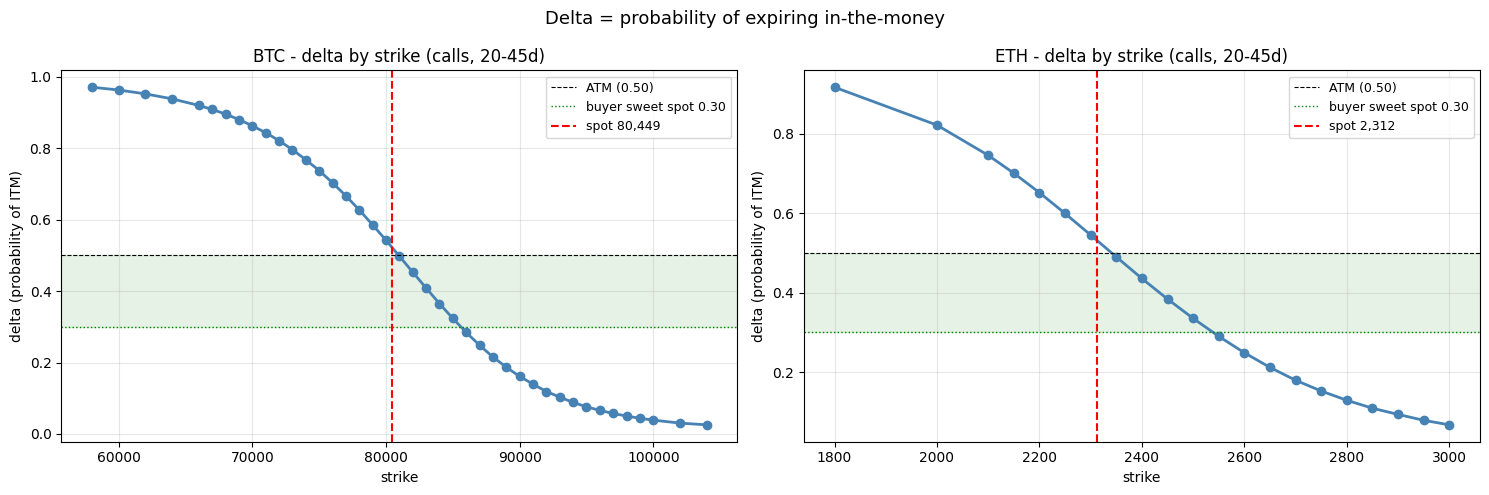

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = ek[(ek.coin == cur) & ek.days.between(20, 45) & (ek.kind == 'C')]
    if len(s) == 0:
        ax.axis('off'); continue
    spot = spots[cur]
    s = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)].sort_values('strike')

    ax.plot(s.strike, s.delta, marker='o', lw=2, color='steelblue', ms=6)
    ax.axhline(0.5, color='black', ls='--', lw=0.8, label='ATM (0.50)')
    ax.axhline(0.3, color='green', ls=':', lw=1, label='buyer sweet spot 0.30')
    ax.axvline(spot, color='red', lw=1.5, ls='--', label=f'spot {spot:,.0f}')
    ax.axhspan(0.3, 0.5, color='green', alpha=0.1)
    ax.set_title(f'{cur} - delta by strike (calls, 20-45d)')
    ax.set_xlabel('strike')
    ax.set_ylabel('delta (probability of ITM)')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Delta = probability of expiring in-the-money', fontsize=13)
plt.tight_layout(); plt.show()

## 4. Gamma concentration - where delta changes fastest

**What this tells you:**

- **Gamma is highest at ATM** and near expiry
- High gamma = delta changes fast = your position accelerates
- **Positive for buyers** — you want gamma working for you
- Gamma peaks **in the last 7 days** before expiry for ATM strikes
- Deep OTM = low gamma (lottery tickets don't accelerate)

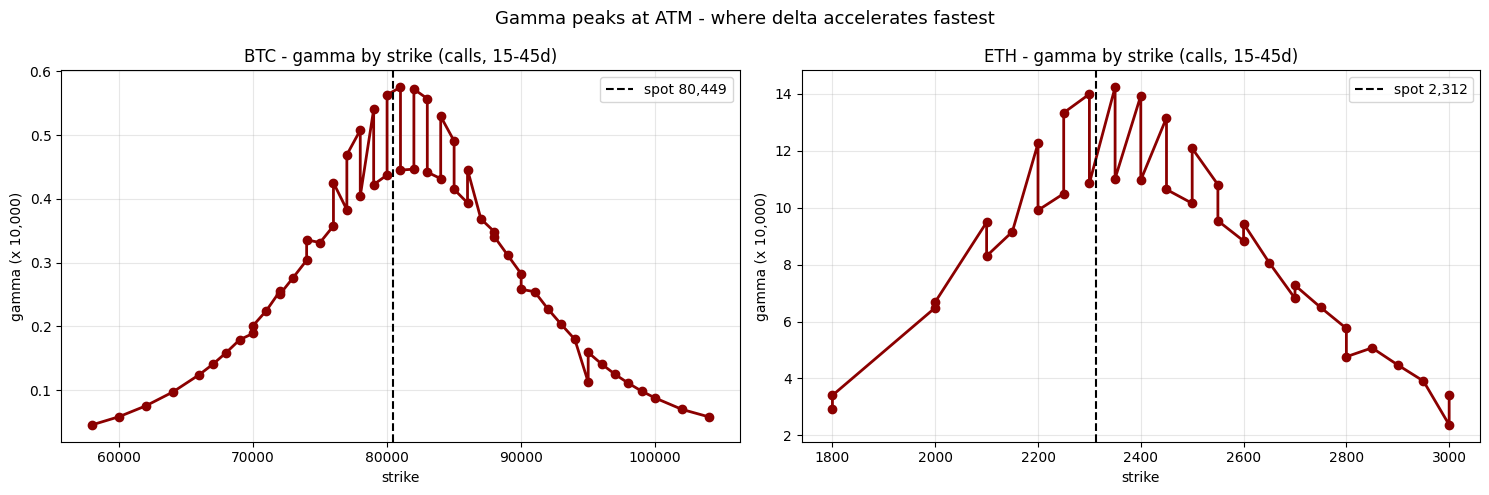

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = ek[(ek.coin == cur) & ek.days.between(15, 45) & (ek.kind == 'C')]
    if len(s) == 0:
        ax.axis('off'); continue
    spot = spots[cur]
    s = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)].sort_values('strike')

    ax.plot(s.strike, s.gamma * 10000, marker='o', lw=2,
            color='darkred', ms=6)
    ax.axvline(spot, color='black', lw=1.5, ls='--', label=f'spot {spot:,.0f}')
    ax.set_title(f'{cur} - gamma by strike (calls, 15-45d)')
    ax.set_xlabel('strike')
    ax.set_ylabel('gamma (x 10,000)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Gamma peaks at ATM - where delta accelerates fastest', fontsize=13)
plt.tight_layout(); plt.show()

## 5. Vega exposure - vol sensitivity map

**What this tells you:**

- **Vega = how much premium changes per 1% IV move**
- High vega = more sensitive to volatility → good in low IV, bad in high IV
- Vega is **highest** for ATM, long-dated options
- Vega is **zero** for deep ITM/OTM short-dated
- **As a buyer, high vega is good if you buy in low IV and vol rises**

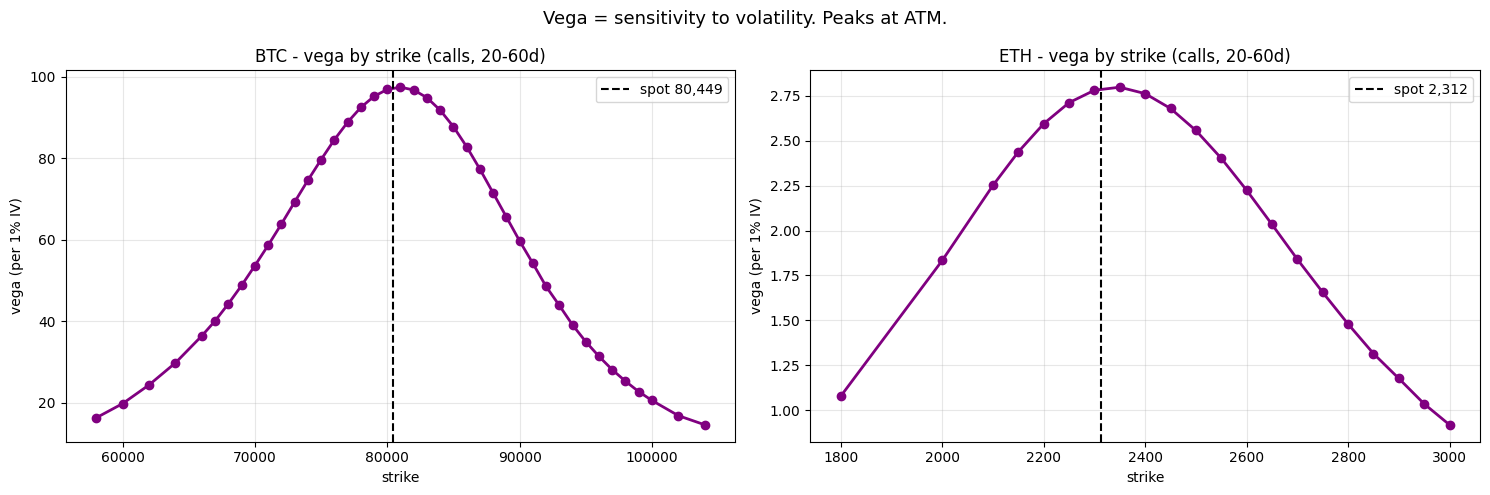

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = ek[(ek.coin == cur) & ek.days.between(20, 60) & (ek.kind == 'C')]
    if len(s) == 0:
        ax.axis('off'); continue
    spot = spots[cur]
    s = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)].sort_values('strike')

    ax.plot(s.strike, s.vega, marker='o', lw=2, color='purple', ms=6)
    ax.axvline(spot, color='black', lw=1.5, ls='--', label=f'spot {spot:,.0f}')
    ax.set_title(f'{cur} - vega by strike (calls, 20-60d)')
    ax.set_xlabel('strike')
    ax.set_ylabel('vega (per 1% IV)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Vega = sensitivity to volatility. Peaks at ATM.', fontsize=13)
plt.tight_layout(); plt.show()

## 6. Theta decay - your daily cost as a buyer

**What this tells you:**

- **Theta = premium lost per day** (always negative for buyers)
- Theta is **most negative ATM** (worst time decay)
- Theta is **worst in last 30 days** (accelerates near expiry)
- **As a buyer:** theta is your enemy. Pay attention to how much you lose per day
- Best contracts have **small theta relative to delta** (cheap carry)

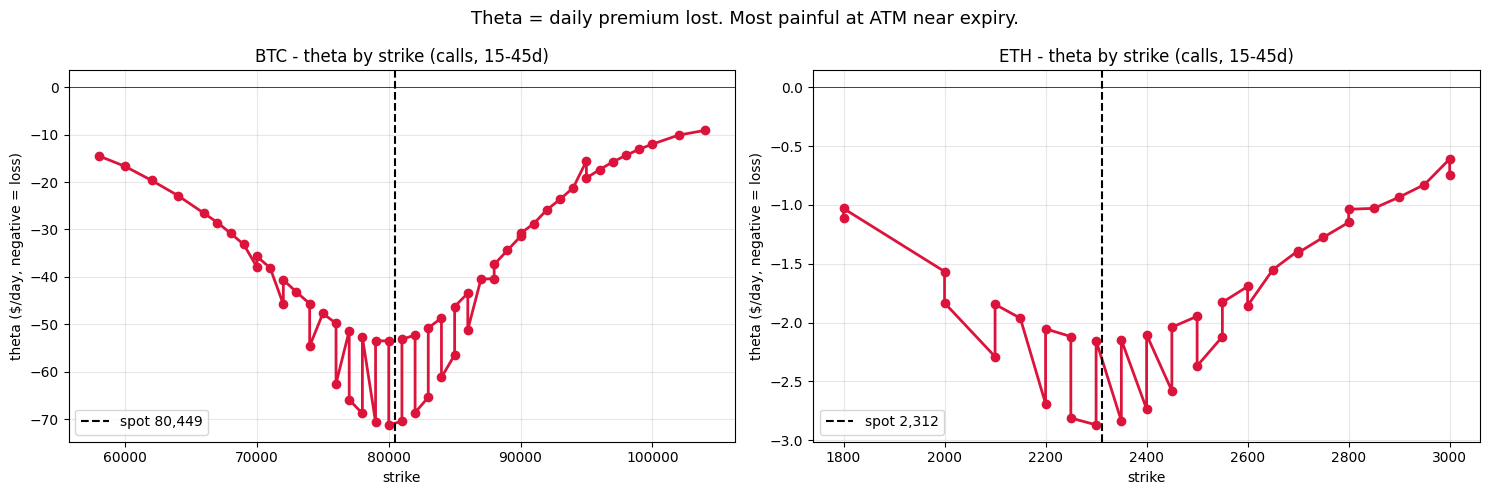

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, cur in zip(axes, COINS):
    s = ek[(ek.coin == cur) & ek.days.between(15, 45) & (ek.kind == 'C')]
    if len(s) == 0:
        ax.axis('off'); continue
    spot = spots[cur]
    s = s[(s.strike > spot * 0.7) & (s.strike < spot * 1.3)].sort_values('strike')

    ax.plot(s.strike, s.theta, marker='o', lw=2, color='crimson', ms=6)
    ax.axvline(spot, color='black', lw=1.5, ls='--', label=f'spot {spot:,.0f}')
    ax.axhline(0, color='black', lw=0.5)
    ax.set_title(f'{cur} - theta by strike (calls, 15-45d)')
    ax.set_xlabel('strike')
    ax.set_ylabel('theta ($/day, negative = loss)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Theta = daily premium lost. Most painful at ATM near expiry.', fontsize=13)
plt.tight_layout(); plt.show()

## 7. Greeks vs days to expiry

**What this tells you:**

- **Delta** rises toward 1 (calls) or -1 (puts) as expiry approaches for ITM options
- **Gamma** explodes in last 7 days for ATM options
- **Vega** decays to zero as expiry approaches
- **Theta** accelerates (more negative) in last 30 days
- **Tradeoff:** shorter-dated = more theta pain but higher gamma leverage

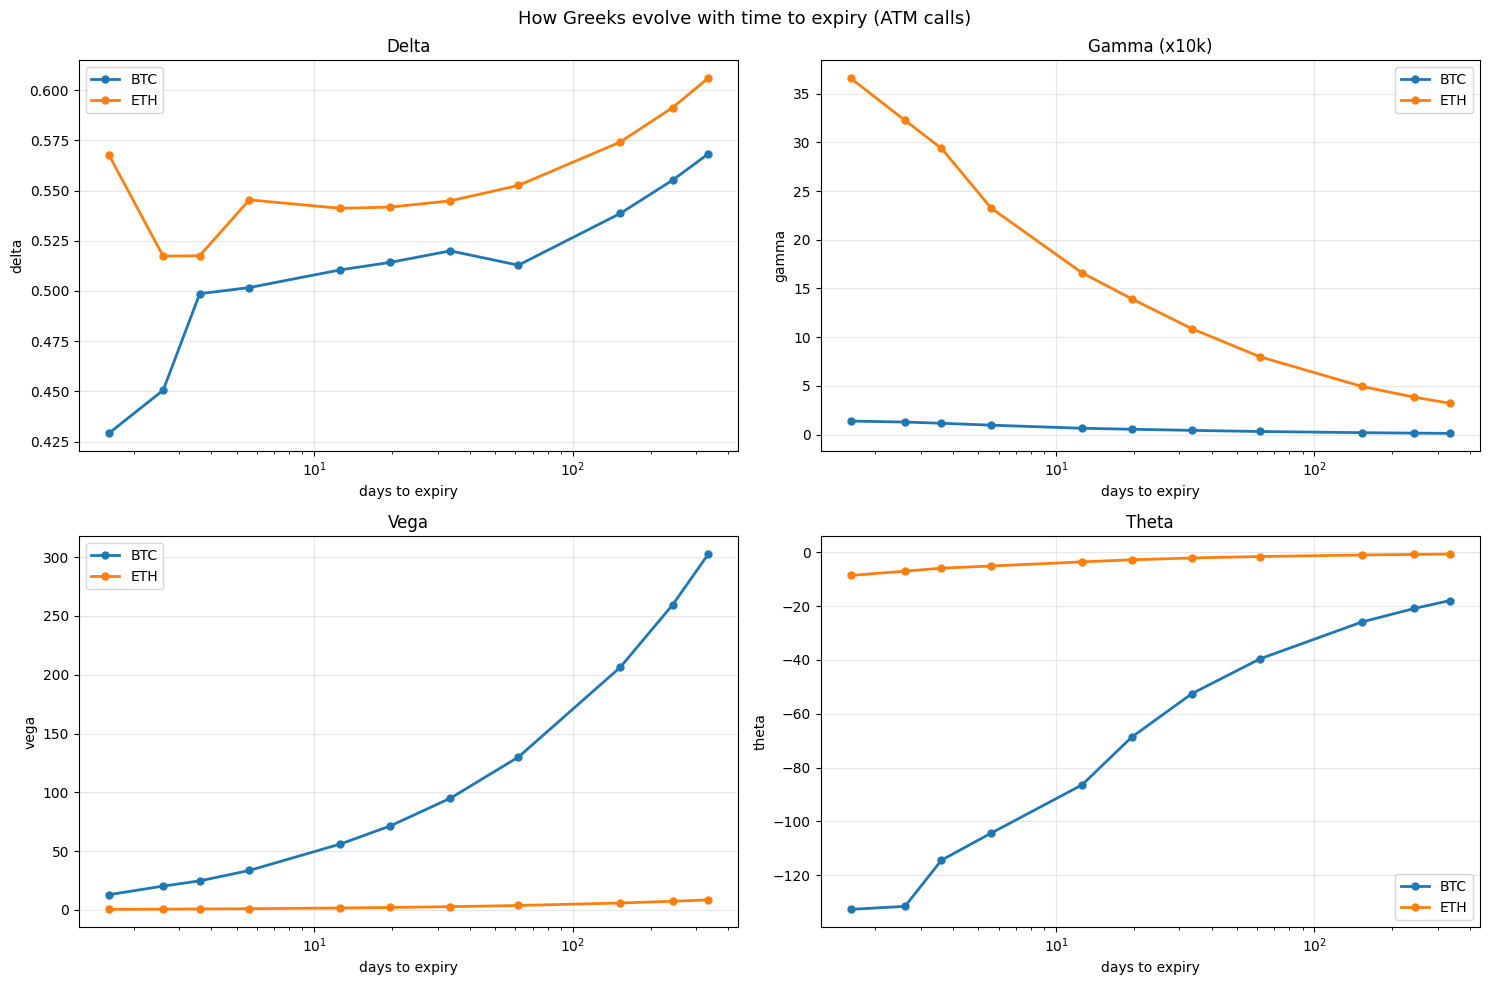

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (metric, title, color) in zip(axes.flatten(), [
    ('delta', 'Delta', 'steelblue'),
    ('gamma', 'Gamma (x10k)', 'darkred'),
    ('vega',  'Vega', 'purple'),
    ('theta', 'Theta', 'crimson'),
    ]):
    for cur in COINS:
        s = ek[(ek.coin == cur) & (ek.kind == 'C')].copy()
        if len(s) == 0: continue
        spot = spots[cur]
        atm = s[(s.strike > spot * 0.95) & (s.strike < spot * 1.05)]
        by_exp = atm.groupby('days')[metric].median()
        by_exp = by_exp[(by_exp.index > 0) & (by_exp.index < 365)]
        if metric == 'gamma':
            by_exp = by_exp * 10000
        ax.plot(by_exp.index, by_exp.values, marker='o', lw=2,
                label=cur, ms=5)
    ax.set_title(title)
    ax.set_xlabel('days to expiry')
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xscale('log')

plt.suptitle('How Greeks evolve with time to expiry (ATM calls)', fontsize=13)
plt.tight_layout(); plt.show()

## 8. Greeks heatmaps - strike × expiry

**What this tells you:**

- Darker = higher value → shows where the action is
- Spot line shows your position relative to the heatmap
- **Delta heatmap**: green near right (ITM), red near left (OTM)
- **Gamma heatmap**: focused peak at ATM, short expiry
- **Vega heatmap**: broad at ATM, longer expiry
- **Theta heatmap**: darkest at ATM, short expiry

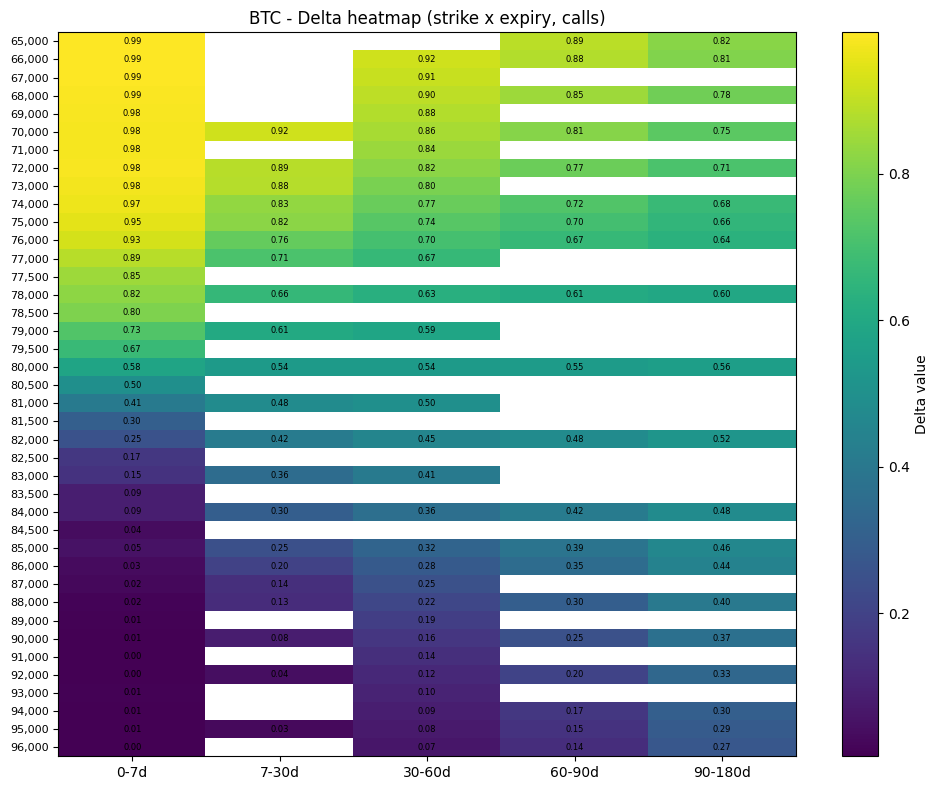

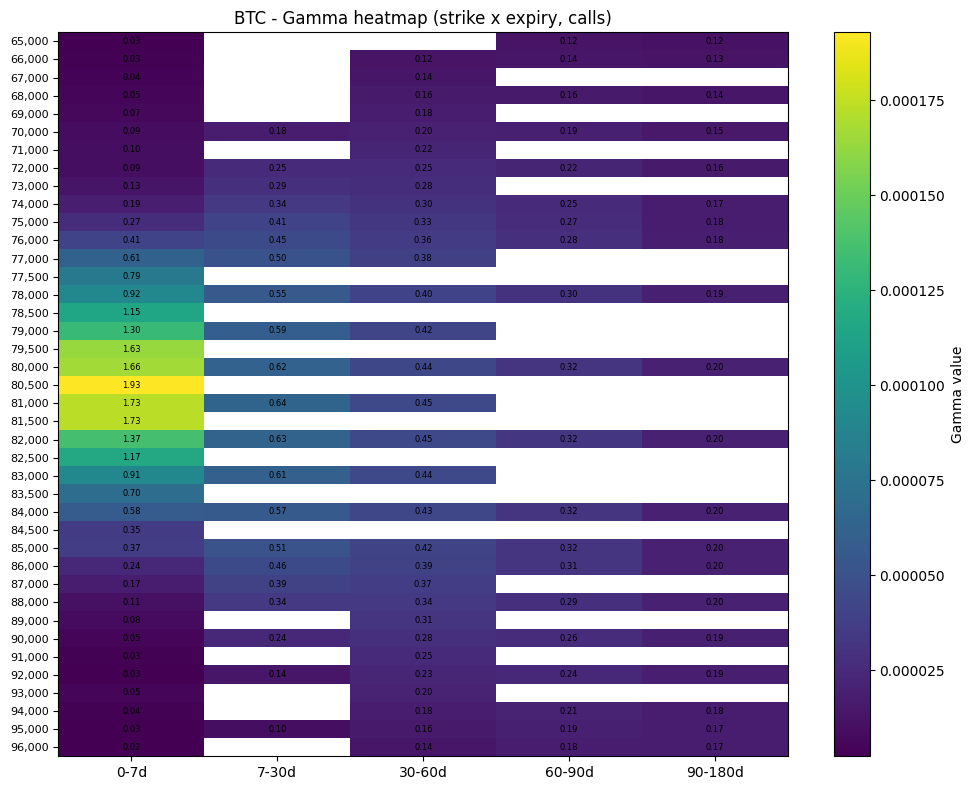

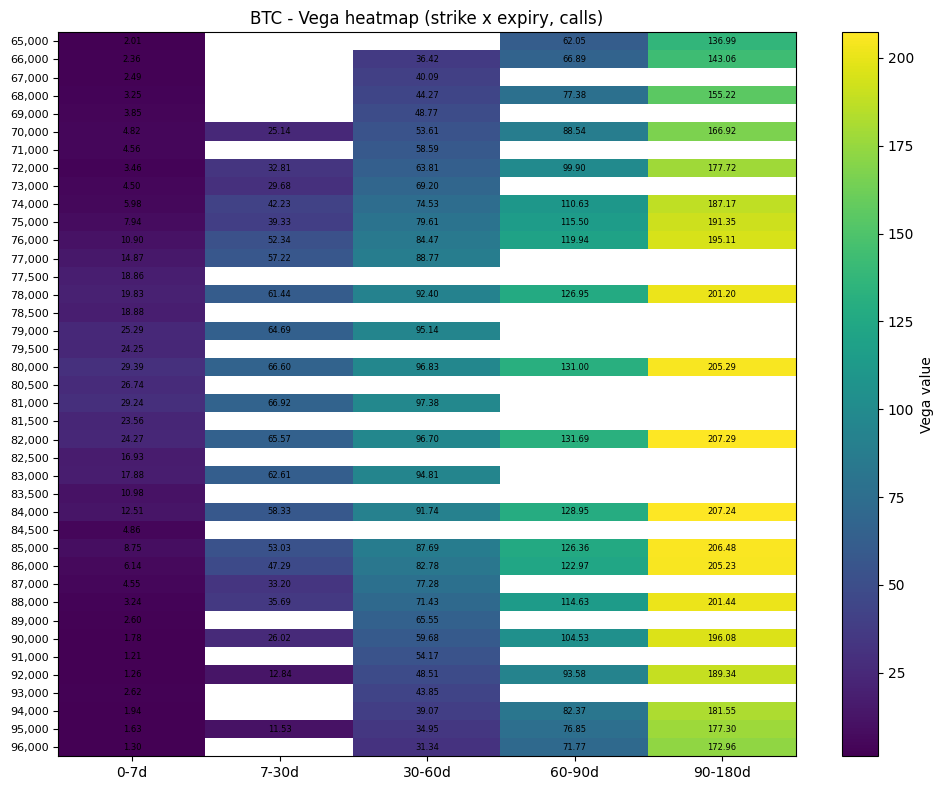

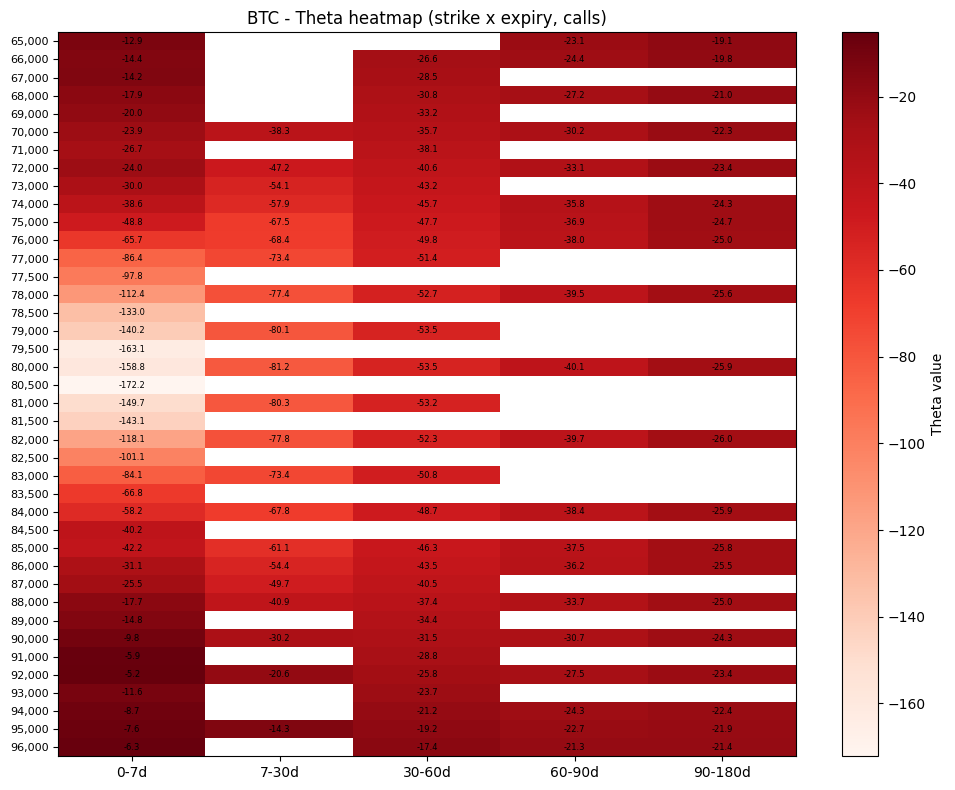

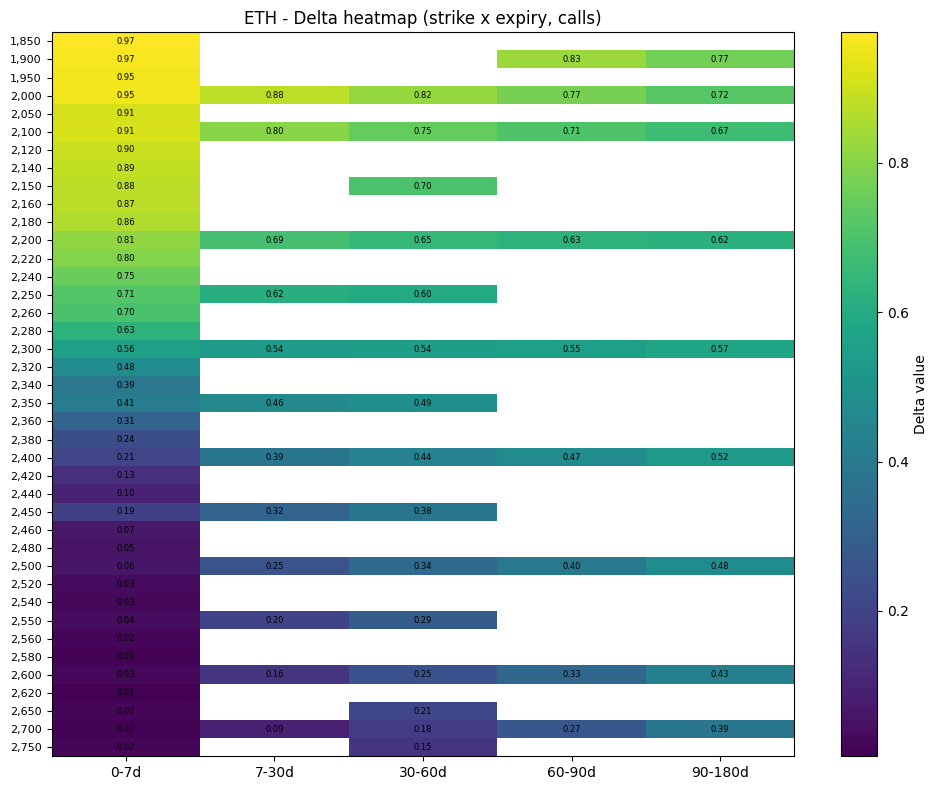

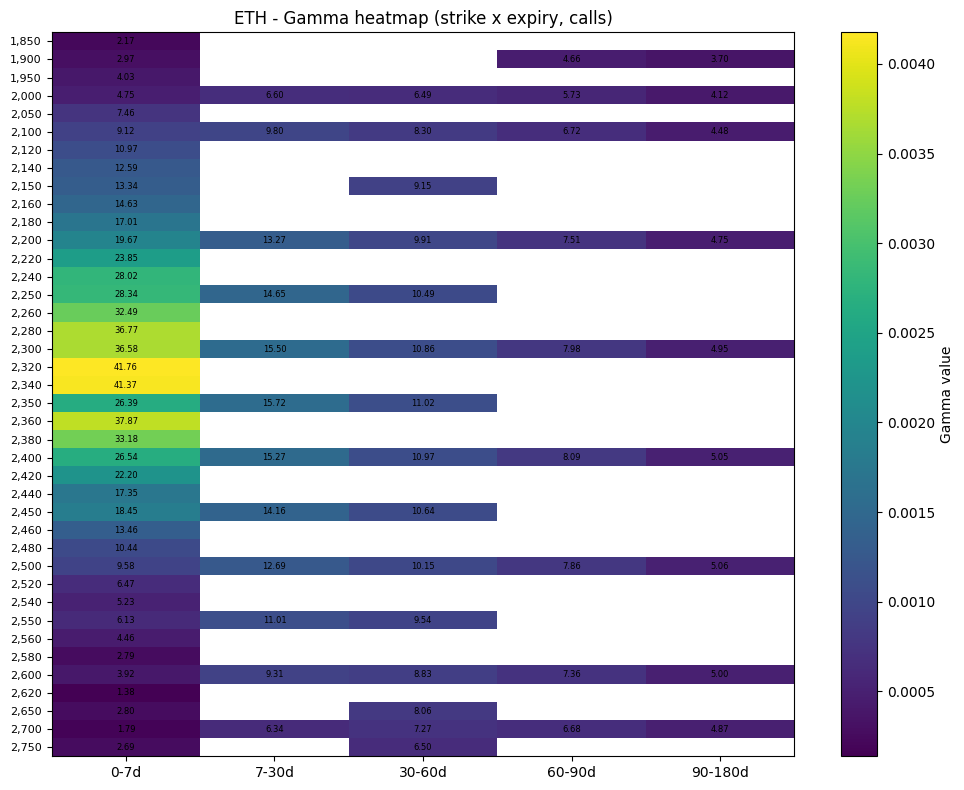

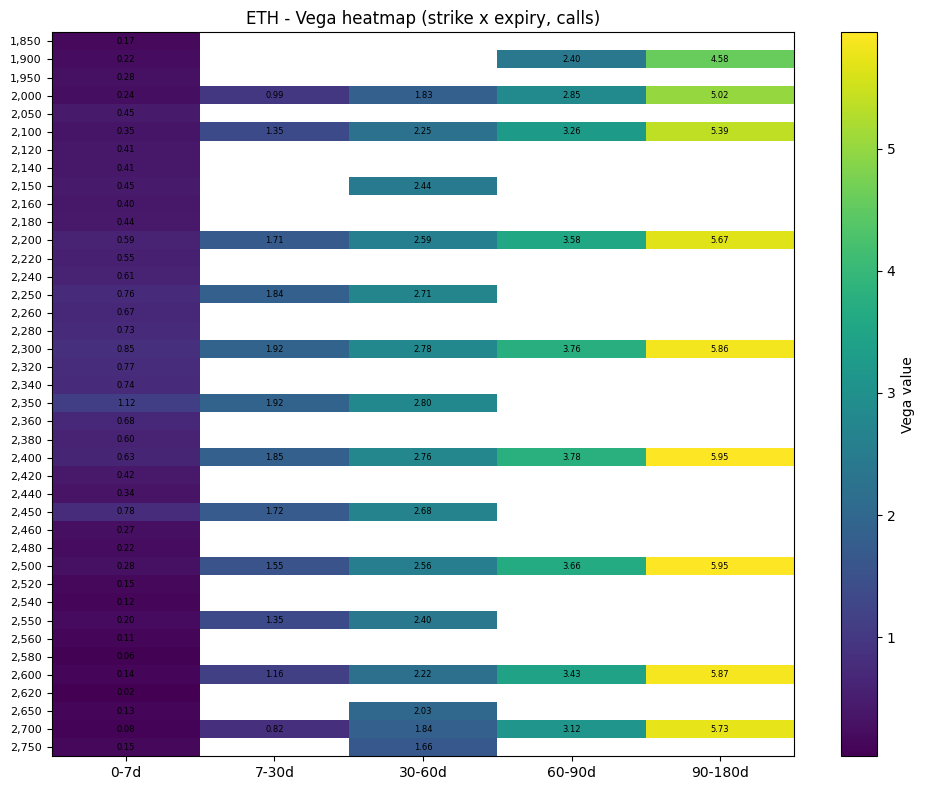

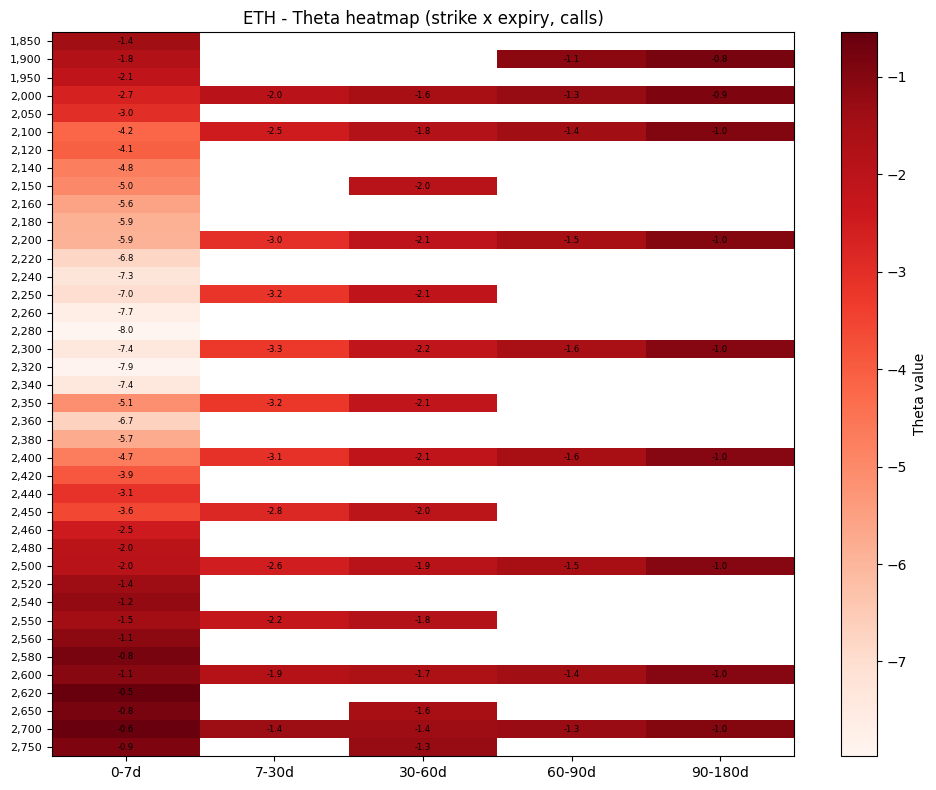

In [10]:
for cur in COINS:
    s = ek[(ek.coin == cur) & (ek.kind == 'C') & ek.days.between(1, 180)].copy()
    spot = spots[cur]
    s = s[(s.strike > spot * 0.8) & (s.strike < spot * 1.2)]
    if len(s) < 10: continue

    s['exp_bucket'] = pd.cut(s.days,
                             bins=[0, 7, 30, 60, 90, 180],
                             labels=['0-7d', '7-30d', '30-60d', '60-90d', '90-180d'])

    for metric, title in [('delta', 'Delta'), ('gamma', 'Gamma'),
                          ('vega', 'Vega'), ('theta', 'Theta')]:
        pivot = s.pivot_table(index='strike', columns='exp_bucket',
                               values=metric, aggfunc='mean', observed=True)
        if len(pivot) == 0: continue

        fig, ax = plt.subplots(figsize=(10, 8))
        if metric == 'theta':
            im = ax.imshow(pivot.values, cmap='Reds', aspect='auto')
        else:
            im = ax.imshow(pivot.values, cmap='viridis', aspect='auto')
        ax.set_xticks(range(len(pivot.columns)))
        ax.set_xticklabels(pivot.columns)
        ax.set_yticks(range(len(pivot.index)))
        ax.set_yticklabels([f'{s:,.0f}' for s in pivot.index], fontsize=8)
        for i in range(pivot.shape[0]):
            for j in range(pivot.shape[1]):
                v = pivot.iloc[i, j]
                if pd.notna(v):
                    if metric == 'gamma':
                        txt = f'{v*10000:.2f}'
                    elif metric == 'theta':
                        txt = f'{v:.1f}'
                    else:
                        txt = f'{v:.2f}'
                    ax.text(j, i, txt, ha='center', va='center', fontsize=6,
                            color='white' if v > pivot.values.mean() else 'black')
        plt.colorbar(im, ax=ax, label=f'{title} value')
        ax.set_title(f'{cur} - {title} heatmap (strike x expiry, calls)')
        plt.tight_layout(); plt.show()

## 9. Best contracts by Greeks profile

**Buyer's ideal contract:**

- Delta 0.30-0.50 (real leverage)
- **High gamma relative to theta** (efficient acceleration)
- **Positive vega** (sensitive to IV expansion)
- **Low theta per delta** (cheap carry)

Each contract gets a buyer score combining these.

In [11]:
ek_buy = ek[(ek.days.between(15, 60)) & ek.delta.notna() & ek.theta.notna()].copy()

# target delta 0.40
ek_buy['delta_fit'] = 1 - abs(ek_buy.delta.abs() - 0.40) / 0.40
ek_buy['gamma_theta_ratio'] = ek_buy.gamma / (ek_buy.theta.abs() + 1e-9)

# normalize
for col in ['delta_fit', 'gamma_theta_ratio', 'vega', 'theta']:
    v = ek_buy[col].abs()
    ek_buy[f'{col}_norm'] = (v - v.min()) / (v.max() - v.min() + 1e-9)

# score: high delta_fit + high gamma/theta + high vega + LOW theta
ek_buy['buyer_score'] = (
    0.35 * ek_buy.delta_fit
    + 0.30 * ek_buy.gamma_theta_ratio_norm
    + 0.20 * ek_buy.vega_norm
    + 0.15 * (1 - ek_buy.theta_norm)
)

for cur in COINS:
    print(f'\n{cur} top contracts by buyer score:')
    s = ek_buy[ek_buy.coin == cur].sort_values('buyer_score', ascending=False).head(5)
    print(s[['strike','kind','days','iv_dec','delta','gamma','vega','theta','buyer_score']].round(4).to_string(index=False))


BTC top contracts by buyer score:
 strike kind    days  iv_dec   delta  gamma    vega    theta  buyer_score
83000.0    C 33.6014  0.3600  0.4086    0.0 94.8091 -50.7885       0.5807
79000.0    P 33.6014  0.3779 -0.4146    0.0 95.1367 -53.4980       0.5703
84000.0    C 33.6014  0.3565  0.3649    0.0 91.7426 -48.6680       0.5557
78000.0    P 33.6014  0.3834 -0.3730    0.0 92.4024 -52.7167       0.5555
82000.0    C 33.6014  0.3633  0.4530    0.0 96.7004 -52.2765       0.5426

ETH top contracts by buyer score:
 strike kind    days  iv_dec   delta  gamma   vega   theta  buyer_score
 2400.0    C 19.6014  0.5176  0.4012 0.0014 2.0718 -2.7354       0.7905
 2450.0    C 33.6014  0.5116  0.3840 0.0011 2.6797 -2.0400       0.7871
 2250.0    P 33.6014  0.5250 -0.4009 0.0010 2.7120 -2.1187       0.7852
 2400.0    C 33.6014  0.5116  0.4356 0.0011 2.7623 -2.1029       0.7701
 2250.0    P 19.6014  0.5365 -0.3890 0.0013 2.0545 -2.8116       0.7614


## 10. Greeks profile of top pick

Visual summary of the best contract's Greeks.

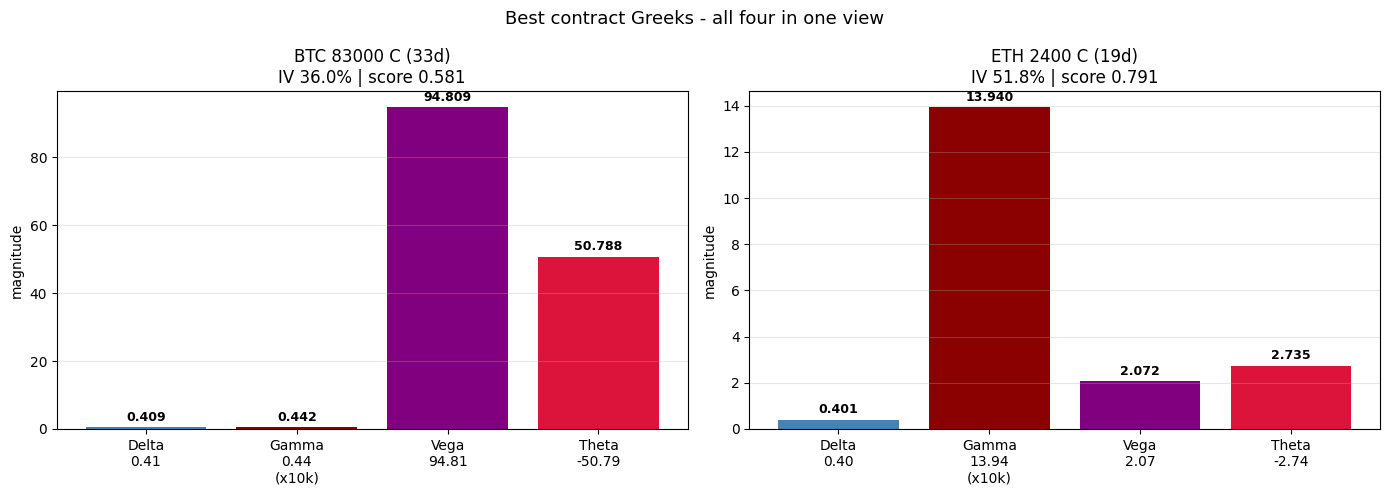

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cur in zip(axes, COINS):
    s = ek_buy[ek_buy.coin == cur].sort_values('buyer_score', ascending=False)
    if len(s) == 0:
        ax.axis('off'); continue
    top = s.iloc[0]

    metrics = ['delta', 'gamma', 'vega', 'theta']
    vals = [abs(top.delta), abs(top.gamma) * 10000, abs(top.vega), abs(top.theta)]
    labels = [f'Delta\n{top.delta:.2f}',
              f'Gamma\n{top.gamma*10000:.2f}\n(x10k)',
              f'Vega\n{top.vega:.2f}',
              f'Theta\n{top.theta:.2f}']
    colors = ['steelblue', 'darkred', 'purple', 'crimson']

    bars = ax.bar(labels, vals, color=colors)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + max(vals) * 0.02,
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')

    ax.set_title(f'{cur} {int(top.strike)} {top.kind} ({int(top.days)}d)\n'
                 f'IV {top.iv_dec*100:.1f}% | score {top.buyer_score:.3f}')
    ax.set_ylabel('magnitude')
    ax.grid(alpha=0.3, axis='y')

plt.suptitle('Best contract Greeks - all four in one view', fontsize=13)
plt.tight_layout(); plt.show()

## 11. FINAL VERDICT

One clear best contract per coin, with all Greeks explained.

In [13]:
print('=' * 72)
print('GREEKS VERDICT - BEST CONTRACT PER COIN')
print('=' * 72)

for cur in COINS:
    s = ek_buy[ek_buy.coin == cur].sort_values('buyer_score', ascending=False)
    if len(s) == 0: continue
    top = s.iloc[0]
    spot = spots[cur]
    dist = (top.strike - spot) / spot * 100

    print(f'\n{cur}  (spot {spot:,.0f})')
    print(f'  Contract   : {int(top.strike)} {top.kind}  ({int(top.days)}d)')
    print(f'  Premium    : ${top.mark:.2f}  (IV {top.iv_dec*100:.1f}%)')
    print(f'  Strike     : {dist:+.1f}% from spot')
    print(f'  Greeks:')
    print(f'    Delta  {top.delta:+.3f}    -> {abs(top.delta)*100:.0f}% chance of ITM')
    print(f'    Gamma  {top.gamma:.5f}   -> delta moves {top.gamma*spot*100:.4f} per 1% spot move')
    print(f'    Vega   {top.vega:.4f}    -> premium moves ${top.vega:.2f} per 1% IV move')
    print(f'    Theta  {top.theta:+.4f}   -> lose ${abs(top.theta):.2f} per day')
    print(f'  Buyer score: {top.buyer_score:.3f}')
    print()
    print(f'  If spot moves +5% immediately:')
    new_premium = top.mark + top.delta * spot * 0.05
    print(f'    Delta gain : +${top.delta * spot * 0.05:.2f}')
    print(f'    Gamma gain : +${0.5 * top.gamma * (spot*0.05)**2:.2f}')
    print(f'    Theta loss : -${abs(top.theta):.2f} (1 day)')
    print(f'    Expected   : ~${new_premium:.2f}')

GREEKS VERDICT - BEST CONTRACT PER COIN

BTC  (spot 80,449)
  Contract   : 83000 C  (33d)
  Premium    : $0.03  (IV 36.0%)
  Strike     : +3.2% from spot
  Greeks:
    Delta  +0.409    -> 41% chance of ITM
    Gamma  0.00004   -> delta moves 355.6024 per 1% spot move
    Vega   94.8091    -> premium moves $94.81 per 1% IV move
    Theta  -50.7885   -> lose $50.79 per day
  Buyer score: 0.581

  If spot moves +5% immediately:
    Delta gain : +$1643.43
    Gamma gain : +$357.60
    Theta loss : -$50.79 (1 day)
    Expected   : ~$1643.46

ETH  (spot 2,312)
  Contract   : 2400 C  (19d)
  Premium    : $0.03  (IV 51.8%)
  Strike     : +3.8% from spot
  Greeks:
    Delta  +0.401    -> 40% chance of ITM
    Gamma  0.00139   -> delta moves 322.3369 per 1% spot move
    Vega   2.0718    -> premium moves $2.07 per 1% IV move
    Theta  -2.7354   -> lose $2.74 per day
  Buyer score: 0.791

  If spot moves +5% immediately:
    Delta gain : +$46.38
    Gamma gain : +$9.32
    Theta loss : -$2.74 (1

## 12. Greeks interpretation guide

Reference table for how to use each Greek as a buyer.

In [14]:
print('=' * 72)
print('GREEKS GUIDE FOR BUYERS')
print('=' * 72)
print()
print('DELTA - probability of expiring in-the-money')
print('  0.80-1.00 : deep ITM, expensive, low leverage, safe')
print('  0.50-0.80 : ITM, moderate cost, moderate leverage')
print('  0.30-0.50 : SWEET SPOT - best risk/reward')
print('  0.10-0.30 : OTM, cheap, high leverage, lower probability')
print('  0.00-0.10 : deep OTM, lottery ticket')
print()
print('GAMMA - speed of delta change')
print('  High gamma = delta accelerates = your position speeds up')
print('  Peaks at ATM, especially last 7 days before expiry')
print('  You WANT high gamma as a buyer - momentum kicks in')
print()
print('VEGA - sensitivity to IV')
print('  High vega = big premium changes on vol shifts')
print('  Good if you buy in low IV and IV rises')
print('  Bad if you buy in high IV and IV drops')
print('  Best contracts: high vega + low IV rank')
print()
print('THETA - daily decay (your enemy)')
print('  Always negative for buyers')
print('  Worst in last 30 days and ATM')
print('  Rule: only buy options with enough time that theta < 5% of premium per day')
print('  For 30-60 day contracts, typical theta is 1-3% of premium per day')
print()
print('COMBINED - the buyer\'s ideal profile:')
print('  Delta 0.30-0.50 + high gamma + high vega + low theta')
print('  = real leverage + acceleration + IV sensitivity + cheap carry')

GREEKS GUIDE FOR BUYERS

DELTA - probability of expiring in-the-money
  0.80-1.00 : deep ITM, expensive, low leverage, safe
  0.50-0.80 : ITM, moderate cost, moderate leverage
  0.30-0.50 : SWEET SPOT - best risk/reward
  0.10-0.30 : OTM, cheap, high leverage, lower probability
  0.00-0.10 : deep OTM, lottery ticket

GAMMA - speed of delta change
  High gamma = delta accelerates = your position speeds up
  Peaks at ATM, especially last 7 days before expiry
  You WANT high gamma as a buyer - momentum kicks in

VEGA - sensitivity to IV
  High vega = big premium changes on vol shifts
  Good if you buy in low IV and IV rises
  Bad if you buy in high IV and IV drops
  Best contracts: high vega + low IV rank

THETA - daily decay (your enemy)
  Always negative for buyers
  Worst in last 30 days and ATM
  Rule: only buy options with enough time that theta < 5% of premium per day
  For 30-60 day contracts, typical theta is 1-3% of premium per day

COMBINED - the buyer's ideal profile:
  Delta 0

## Notes

- All Greeks computed live via Black-Scholes with risk-free rate = 0
- European options (Deribit standard)
- **Greeks change in real time** as spot, IV, and time move
- **Re-run before executing** any trade
- No storage - everything is computed from the current snapshot
- Combine with:
  - `pcr.ipynb` for direction (call vs put)
  - `oi_analysis.ipynb` for OI walls / max pain
  - `01_options_buyer_analysis.ipynb` for the full contract selection